1. Plot simple visuals like line chart, bar chart, histogram, scatterplot, correlation plots, pie chart, stacked chart, box plot, dist plot and other relevant plots based on the given data and information.

2. Plot complex visuals by combining various simple visuals and add legends, axis and title to it. 
     Use customization in plots and make them more presentable.

3. Use different data visualization libraries in python like matplotlib, seaborn, plotly,…etc.

4. Find 5 insights from each dataset using bivariate and multivariate data analysis graphs also include correlation inferences.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import plotly

In [3]:
warnings.filterwarnings('ignore')

In [4]:
garment_df = pd.read_csv('garments_worker_productivity.csv')

01. date : Date in MM-DD-YYYY
02. day : Day of the Week
03. quarter : A portion of the month. A month was divided into four quarters
04. department : Associated department with the instance
05. team : Associated team number with the instance
06. no_of_workers : Number of workers in each team
07. no_of_style_change : Number of changes in the style of a particular product
08. targeted_productivity : Targeted productivity set by the Authority for each team for each day.
09. smv : Standard Minute Value, it is the allocated time for a task
10. wip : Work in progress. Includes the number of unfinished items for products
11. over_time : Represents the amount of overtime by each team in minutes
12. incentive : Represents the amount of financial incentive (in BDT) that enables or motivates a particular course of action.
13. idle_time : The amount of time when the production was interrupted due to several reasons
14. idle_men : The number of workers who were idle due to production interruption
15. actual_productivity : The actual % of productivity that was delivered by the workers. It ranges from 0-1.

In [5]:
garment_df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


We have number of workers in decimal or in fraction which is not possible practically, will make it rounded employee.

In [6]:
garment_df.date = pd.DatetimeIndex(garment_df.date)

In [7]:
garment_df.quarter.replace("Quarter5","Quarter1",inplace=True)

In [8]:
garment_df.no_of_workers = round(garment_df.no_of_workers)

In [9]:
garment_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1197 non-null   datetime64[ns]
 1   quarter                1197 non-null   object        
 2   department             1197 non-null   object        
 3   day                    1197 non-null   object        
 4   team                   1197 non-null   int64         
 5   targeted_productivity  1197 non-null   float64       
 6   smv                    1197 non-null   float64       
 7   wip                    691 non-null    float64       
 8   over_time              1197 non-null   int64         
 9   incentive              1197 non-null   int64         
 10  idle_time              1197 non-null   float64       
 11  idle_men               1197 non-null   int64         
 12  no_of_style_change     1197 non-null   int64         
 13  no_

We have NA or null values in the wip feature we will replace all the null values with 0, perhaps if there is no WIP which means the work is completed or not started.

Text(87.0, 0.5, 'Data Frequency')

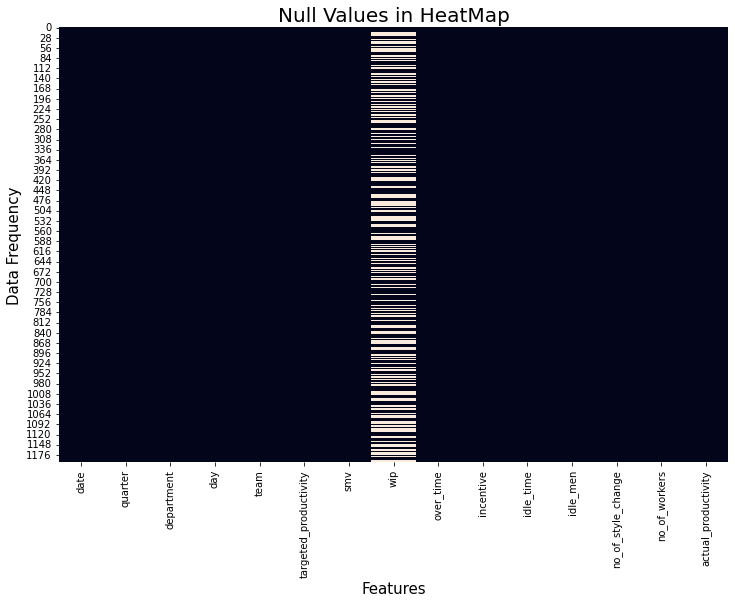

In [10]:
plt.figure(figsize=(12,8))
sns.heatmap(garment_df.isna(),cbar=False)
plt.title("Null Values in HeatMap",fontsize=20)
plt.xlabel("Features",fontsize = 15)
plt.ylabel("Data Frequency",fontsize = 15)

In [11]:
garment_df.wip.fillna(0,inplace=True)

Here we have filled the NA values

In [12]:
finishing_df = garment_df[(garment_df.department =='finishing')]
siwing_df = garment_df[(garment_df.department =='sweing')]

In [13]:
temp_df =pd.DataFrame(finishing_df.groupby(['team'])['actual_productivity'].mean()).reset_index()

temp_df_2 =pd.DataFrame(siwing_df.groupby(['team'])['actual_productivity'].mean()).reset_index()

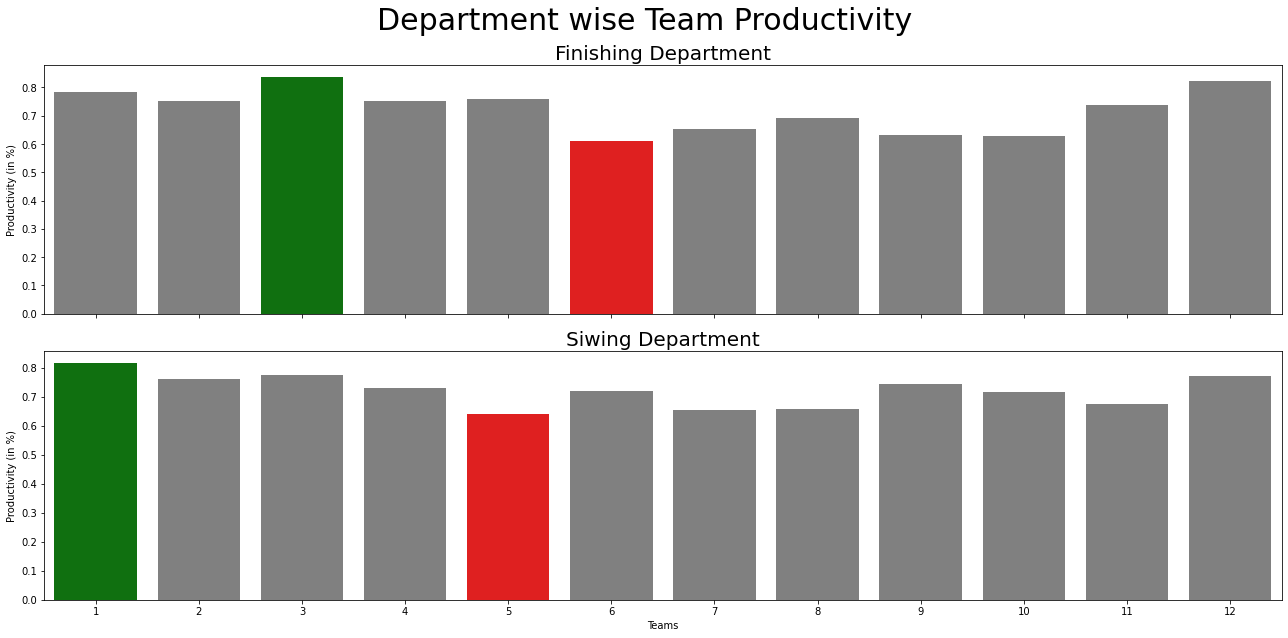

In [14]:
f, axes = plt.subplots(2, 1,figsize=(18,9),sharex=True)
f.suptitle("Department wise Team Productivity",fontsize=30)
clr = ['green' if (x == temp_df.actual_productivity.max()) else ('red' if (x==temp_df.actual_productivity.min()) else 'grey') for x in temp_df.actual_productivity]
sns.barplot(  x="team", y= "actual_productivity", data=temp_df , ax=axes[0],palette=clr)
axes[0].set_title("Finishing Department",fontsize = 20)


f.show()

clr = ['green' if (x == temp_df_2.actual_productivity.max()) else ('red' if (x==temp_df_2.actual_productivity.min()) else 'grey') for x in temp_df_2.actual_productivity]
sns.barplot(  x="team", y= "actual_productivity", data=temp_df_2 , ax=axes[1],palette=clr)
axes[1].set_title("Siwing Department",fontsize = 20)


for ax in axes.flat:
    ax.set(xlabel='Teams', ylabel='Productivity (in %)')
for ax in axes:
    ax.label_outer()
    


f.tight_layout()
f.show()

- Team 3 is highly productive in finishing department where as team 6 has the least productivity in finishing department.
- Team 1 is high productive in Siwing Department where as team 5 is least productive.

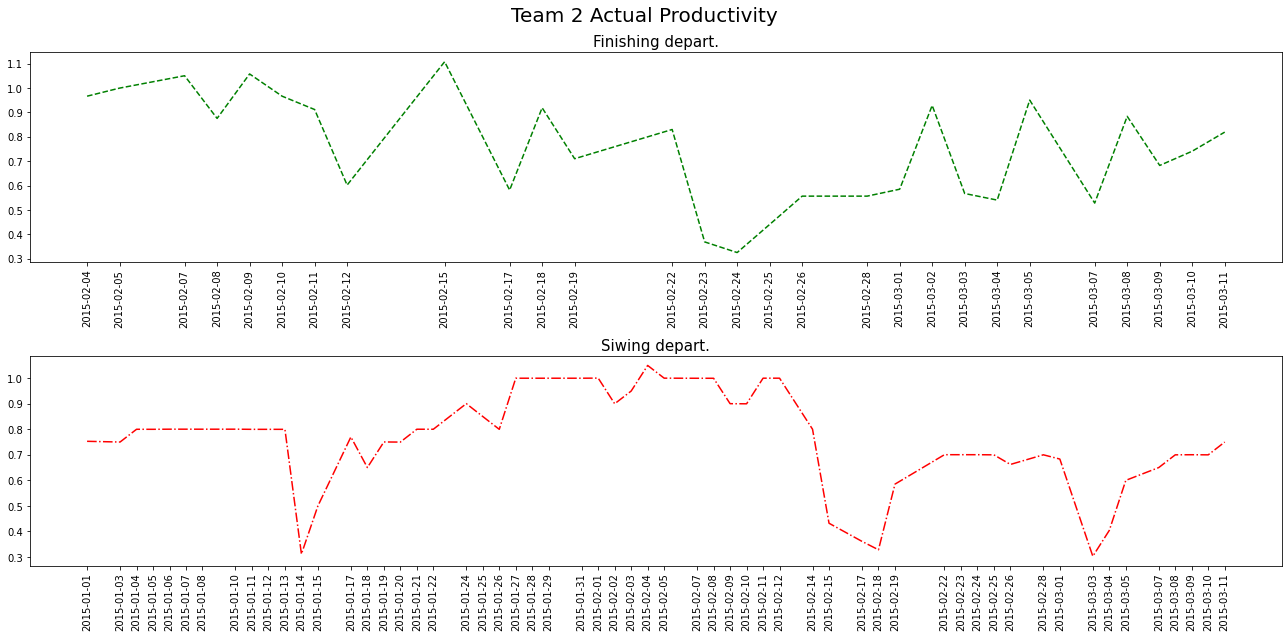

In [15]:
temp_df = garment_df[(garment_df.team ==2)&(garment_df.department =='finishing')]
temp_df_2 = garment_df[(garment_df.team ==2)&(garment_df.department =='sweing')]

f = plt.figure(figsize=(18,9))
plt.suptitle("Team 2 Actual Productivity",fontsize=20)
ax = f.add_subplot(211)
ax.plot(temp_df.date,temp_df.actual_productivity,"-g",ls='--')
plt.title("Finishing depart.",fontsize=15)
plt.xticks(temp_df.date,rotation=90)

ax2 = f.add_subplot(212)
ax2.plot(temp_df_2.date,temp_df_2.actual_productivity,"-r",ls='dashdot')
plt.title("Siwing depart.",fontsize=15)

plt.xticks(temp_df_2.date,rotation=90)

plt.tight_layout()
plt.show()

1. Firstly the dates are not available in the Finishing and Siwing depart.
2. Team 2 has highest productivity in siwing department from 26 jan 2015 to 12 feb 2015 then it falls.
3. Team 2 has highest productivty in Finishing department is on 15 feb 2015.
4. Team 2 has least productivity in siwing department is on 14-january 2015 and in Finishing department have least in 24 february 2015.


In [16]:
garment_df['diff_productivity'] = garment_df.actual_productivity - garment_df.targeted_productivity

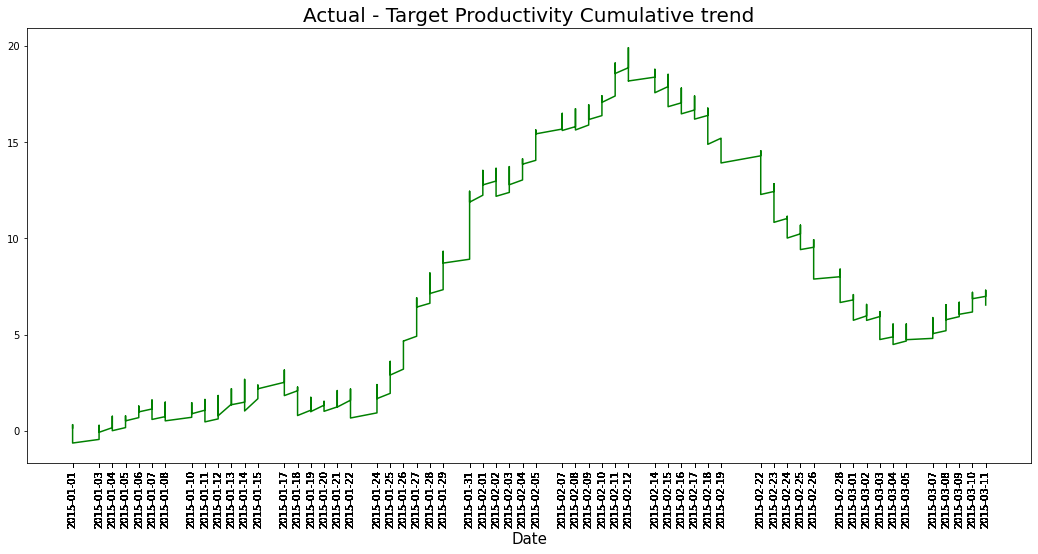

In [17]:
plt.figure(figsize=(18,8))
plt.plot(garment_df.date,garment_df['diff_productivity'].cumsum(axis = 0),"-g")
plt.title("Actual - Target Productivity Cumulative trend",fontsize=20)
plt.xlabel("Date",fontsize=15)
plt.xticks(garment_df.date,rotation=90)
plt.show()

- Here the trend of productivity is increased from january 24 to feb 15 the it start declining.

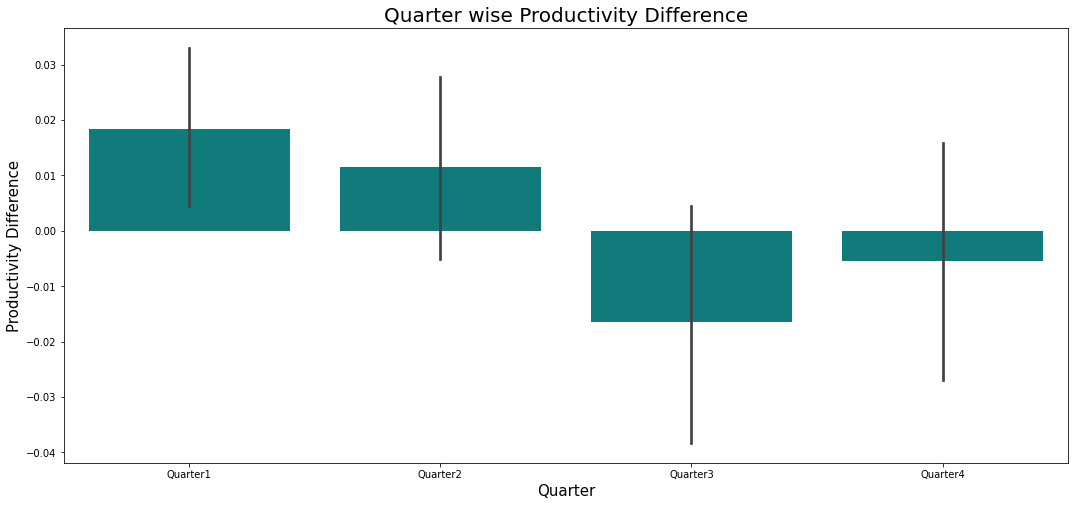

In [18]:
plt.figure(figsize=(18,8))
sns.barplot(garment_df.quarter,garment_df['diff_productivity'],color='darkcyan')
plt.title("Quarter wise Productivity Difference",fontsize=20)
plt.xlabel("Quarter",fontsize=15)
plt.ylabel("Productivity Difference",fontsize=15)
plt.show()

In the First Quarter we have higher positive change in productivity whereas Quarter 3 and Quarter 4 has least change in productivity

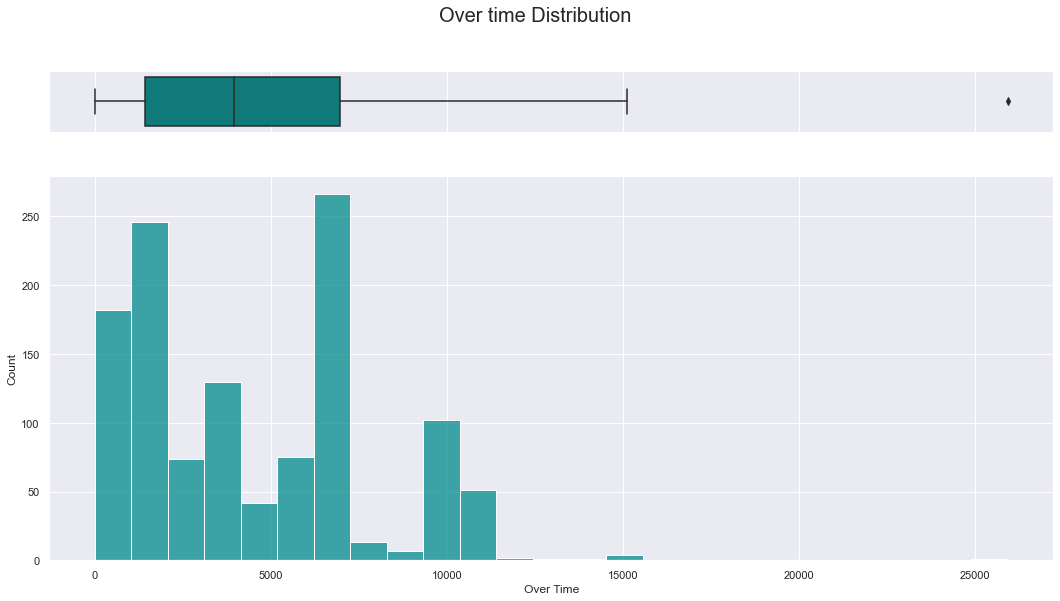

In [128]:
sns.set(style="darkgrid")
f, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .95)},figsize=(18,9))
sns.boxplot( garment_df.over_time, ax=ax_box,color='darkcyan')
sns.histplot(x =garment_df.over_time,color='darkcyan', ax=ax_hist)
plt.suptitle("Over time Distribution").set_size(20)
ax_box.set(xlabel='')
ax_hist.set(xlabel='Over Time',ylabel='Count')
plt.show()

Most Frequent Overtime duration is less than the 2000 minutes where as 6000-7000 has the highest frequency of overtime.has outlier in the feature

In [115]:
num_feature = [feature for feature in garment_df.columns if garment_df[feature].dtype!='O'][2:-1]

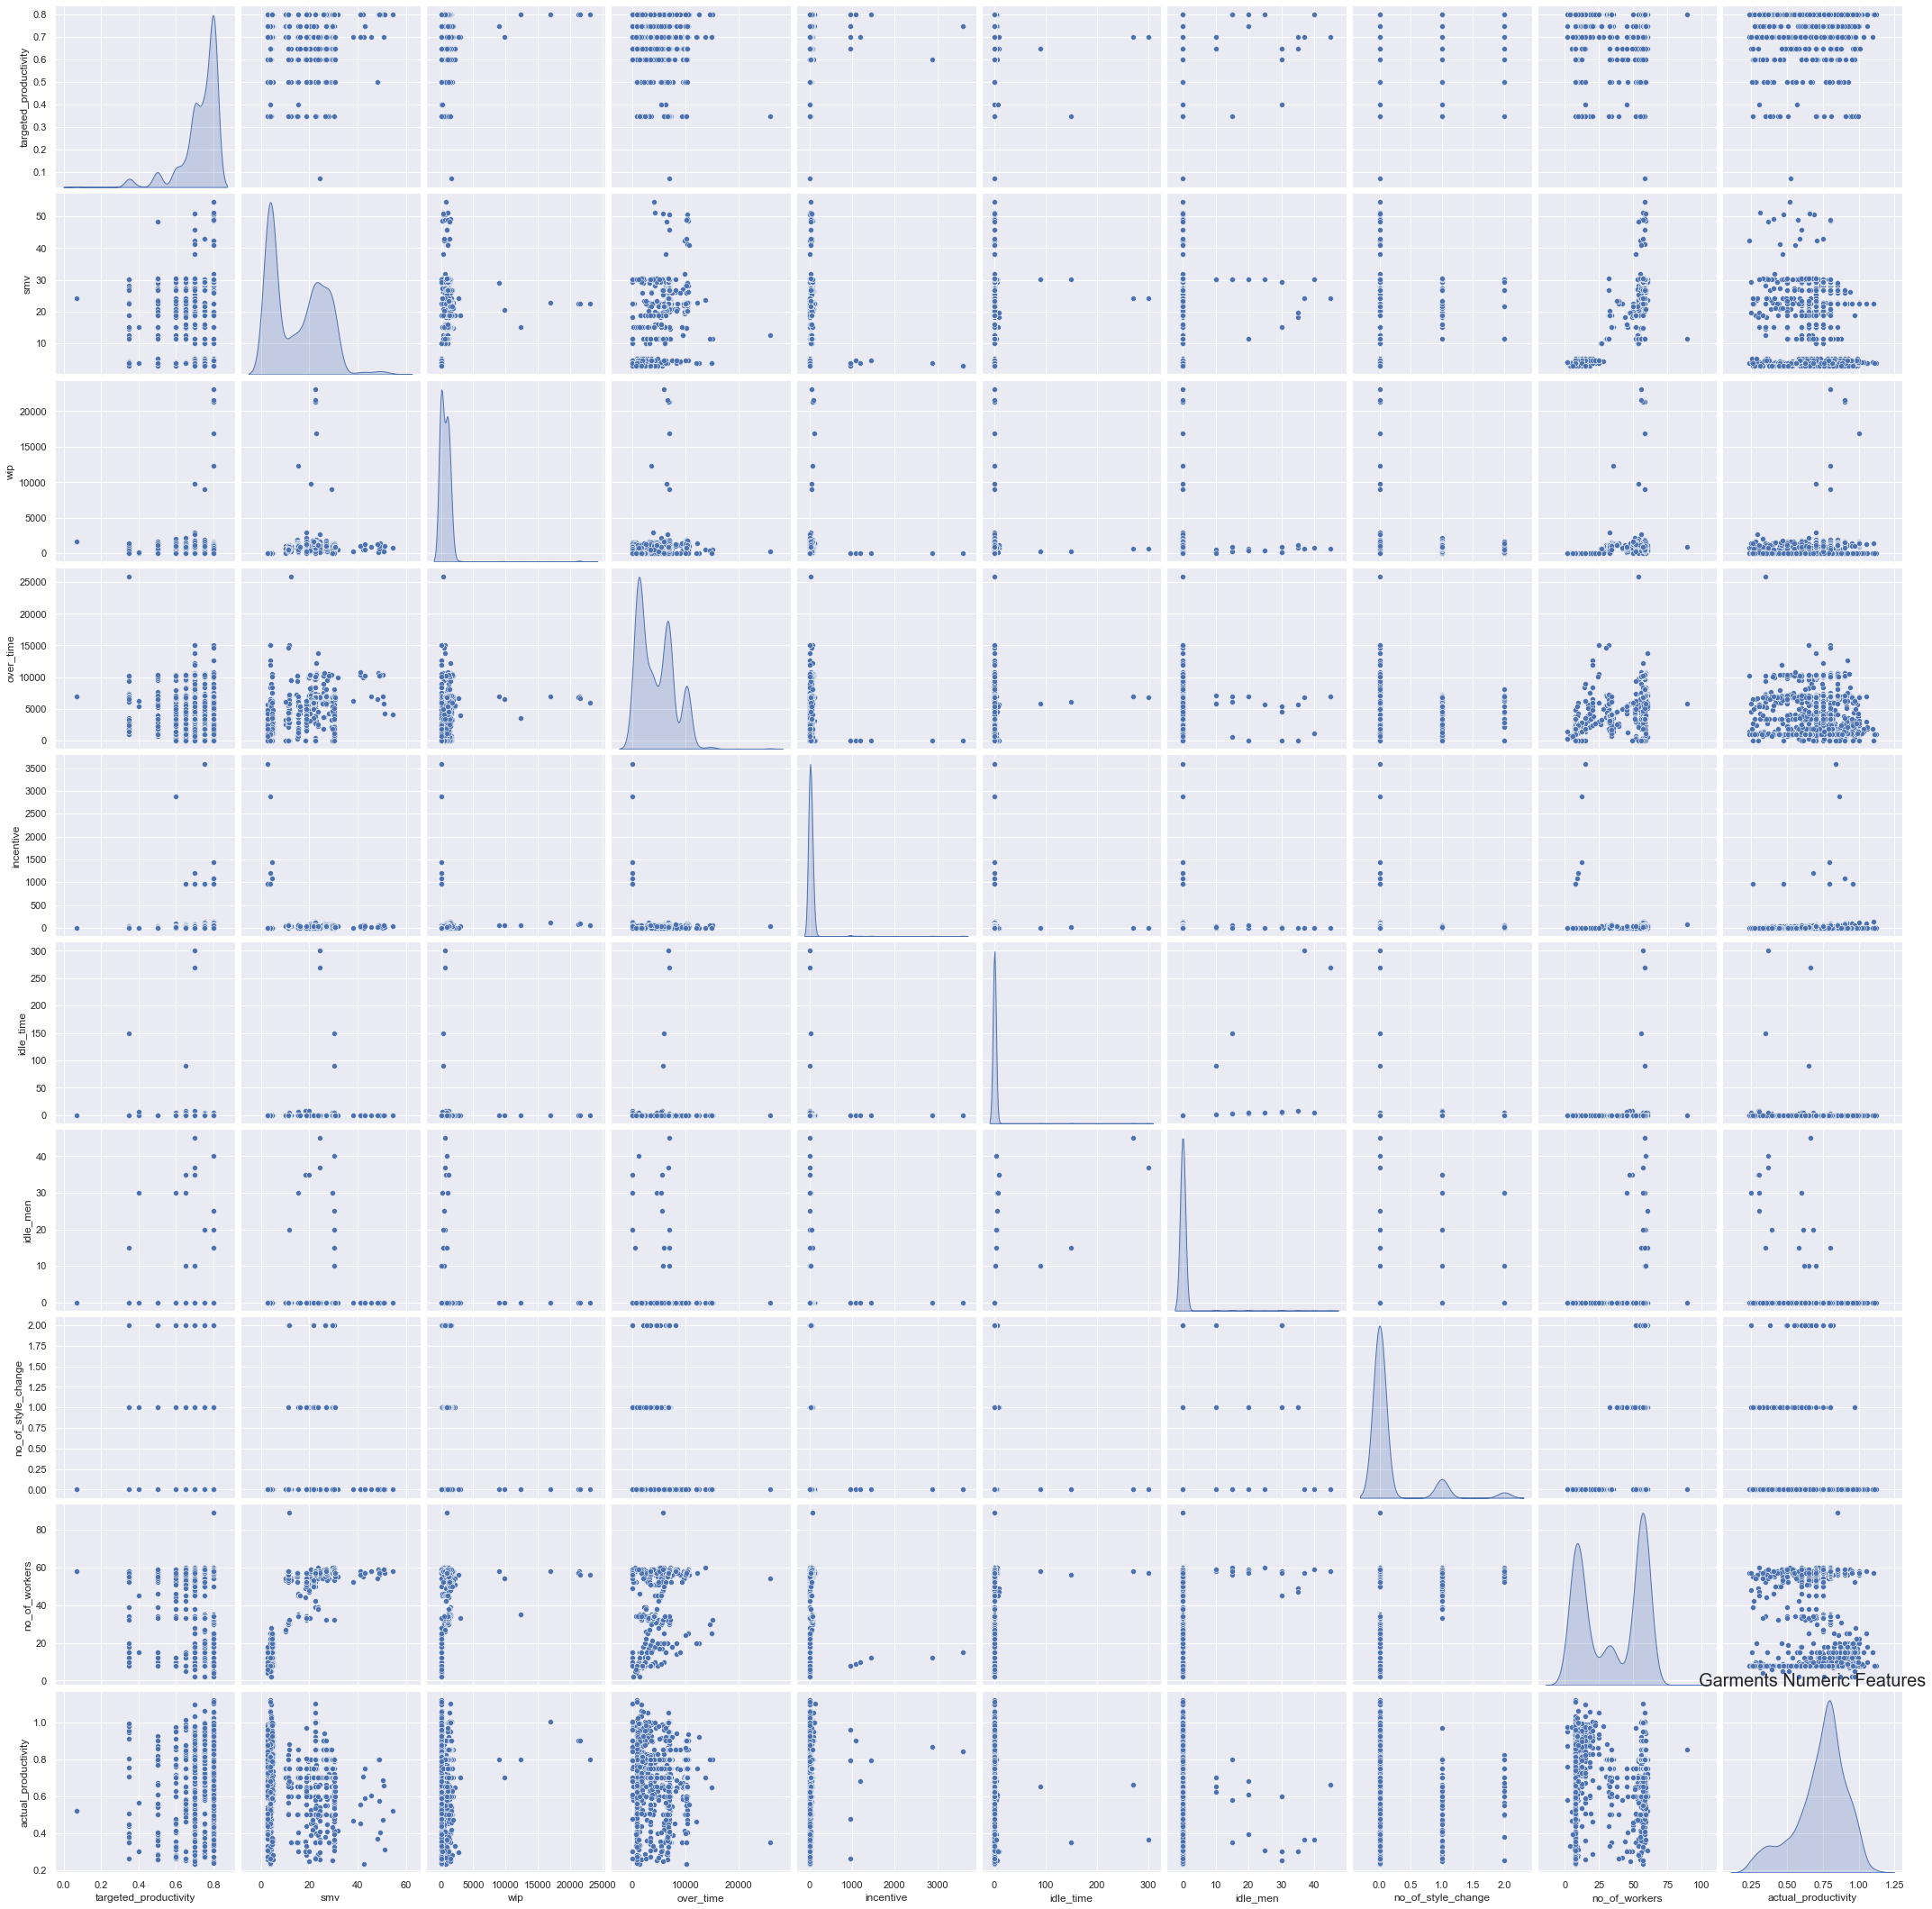

In [129]:
sns.pairplot(garment_df[num_feature],size=3,dropna=True,diag_kind='kde',palette='darkcyan')
plt.title("Garments Numeric Features").set_size(20)
plt.show()

There is no any relation between the features.

In [19]:
df1 = pd.read_csv("winequality-red.csv",sep=";")
df1['wine'] = 'Red_Wine'

In [20]:
df2 = pd.read_csv("winequality-white.csv",sep=";")
df2['wine'] = 'White_Wine'

In [21]:
df = pd.concat([df1,df2])

In [22]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'wine'],
      dtype='object')

In [23]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red_Wine
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red_Wine
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red_Wine
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red_Wine
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red_Wine


In [68]:
import plotly.express as px


# plotting the line chart
fig =px.bar(df, x="wine", y="alcohol",title="Wine Alcohol Based",color='wine',color_discrete_sequence=["red", "darkcyan"])

# showing the plot
fig.show()


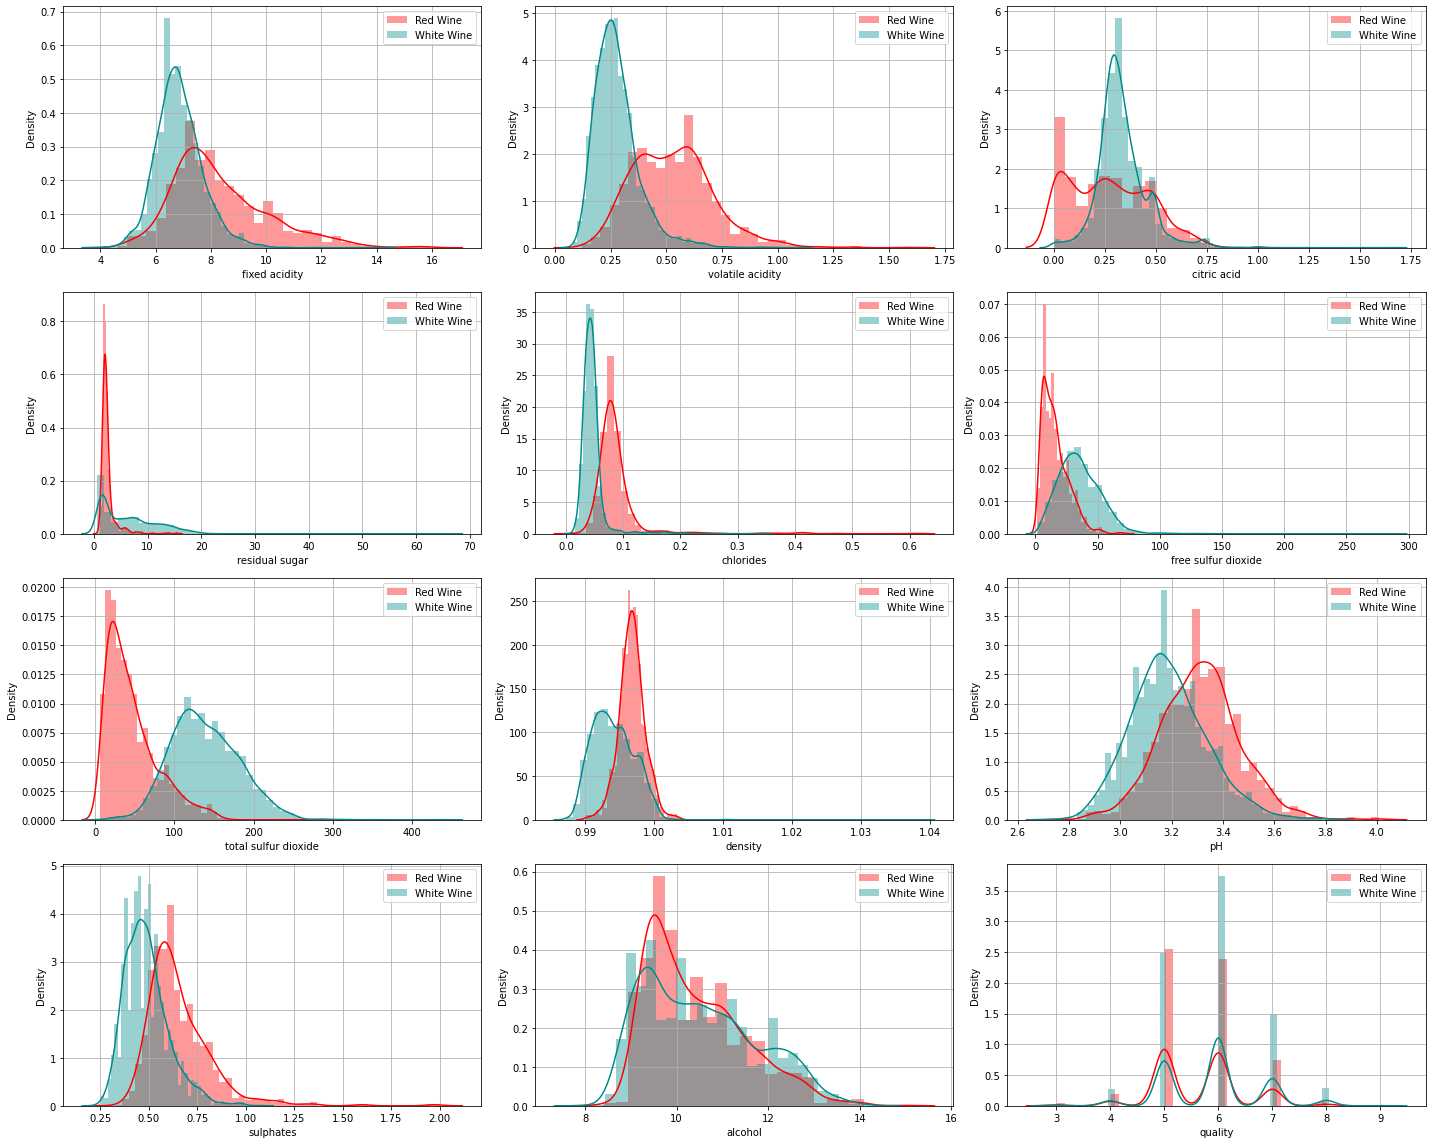

In [26]:
plt.figure(figsize=(20,16))


for i,col in enumerate(list(df.columns.values[:-1])):
    plt.subplot(4,3,i+1)
    sns.distplot(df1[col],color='r',kde=True,label='Red Wine')
    sns.distplot(df2[col],color='darkcyan',kde=True,label='White Wine')
    plt.grid()
    plt.legend(loc = 'upper right')
    plt.tight_layout()

- pH feature is approximately normally distributed.
- Remaining all independent features are positively skewed

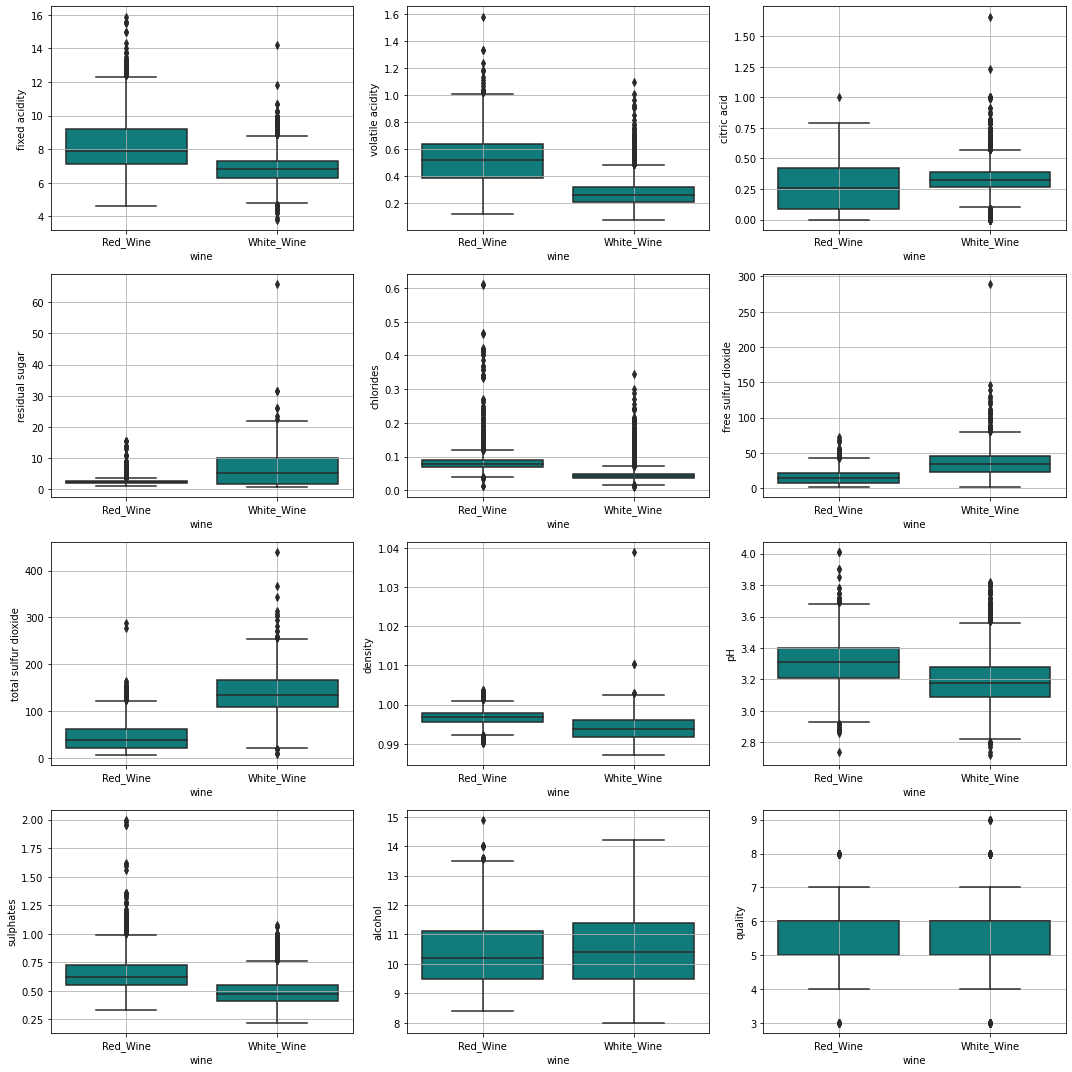

In [27]:
plt.figure(figsize=(15,15))
for i,col in enumerate(list(df.columns.values[:-1])):
    plt.subplot(4,3,i+1)
    sns.boxplot(x =df['wine'], y = df[col],color='darkcyan')
    plt.grid('darkgrid')
    plt.tight_layout()

Outliers are the points outside the 1.5×IQR or more above the third quartile or 1.5×IQR or more below the first quartile.
* Except for alcohol, all other features have outliers.

Text(0.5, 1.0, 'Correlation Plot')

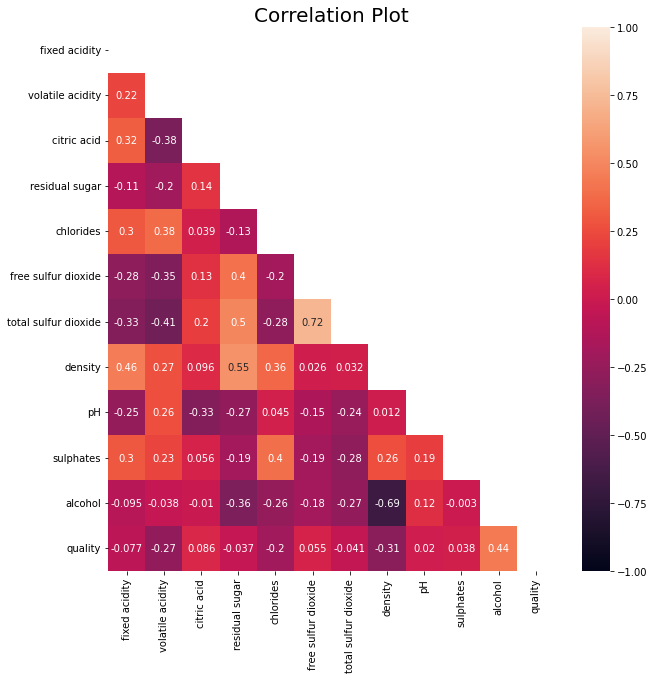

In [28]:
plt.figure(figsize=(10,10))
mask = np.triu(np.ones_like(df.corr()))
sns.heatmap(df.corr(),mask=mask,annot=True,vmin=-1,vmax=1)
plt.title("Correlation Plot", fontsize=20)


* density has a strong positive correlation with residual sugar, whereas it has a strong negative correlation with alcohol.
* pH & fixed acidity has negative correlation.
* density & fixed acidity has positive correlation.
* citric acid & fixed acidity has positive correlation.
* citric acid & volatile acidity has negative correlation.
* free sulphur dioxide & total sulphur dioxide has positive correlation.

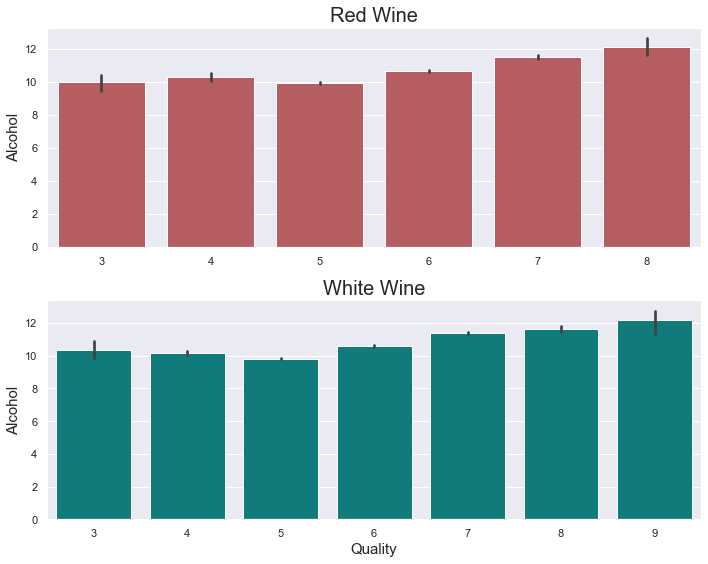

In [88]:
plt.figure(figsize=[10,8])
sns.set_theme(style='darkgrid')
plt.subplot(2,1,1)
sns.barplot(df1['quality'],df1['alcohol'],color='r')
plt.xlabel('').set_size(15)
plt.ylabel('Alcohol').set_size(15)
plt.title("Red Wine").set_size(20)


plt.subplot(2,1,2)
sns.barplot(df2['quality'],df2['alcohol'],color='darkcyan')
plt.xlabel('Quality').set_size(15)
plt.ylabel('Alcohol').set_size(15)
plt.title("White Wine").set_size(20)
plt.tight_layout()


plt.show()

Quality has higher concentration of alcohol in Red wine where as quality 9 has highest in the White Wine.


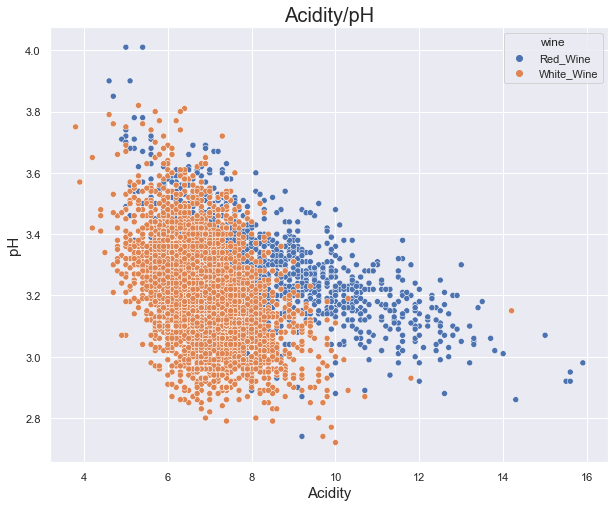

In [34]:
plt.figure(figsize=(10,8))
sns.scatterplot(df['fixed acidity'],df['pH'],hue=df['wine'])
plt.xlabel('Acidity').set_size(15)
plt.ylabel('pH').set_size(15)
plt.title("Acidity/pH").set_size(20)

However, there is no direct connection between total acidity and pH (it is possible to find wines with a high pH for wine and high acidity).

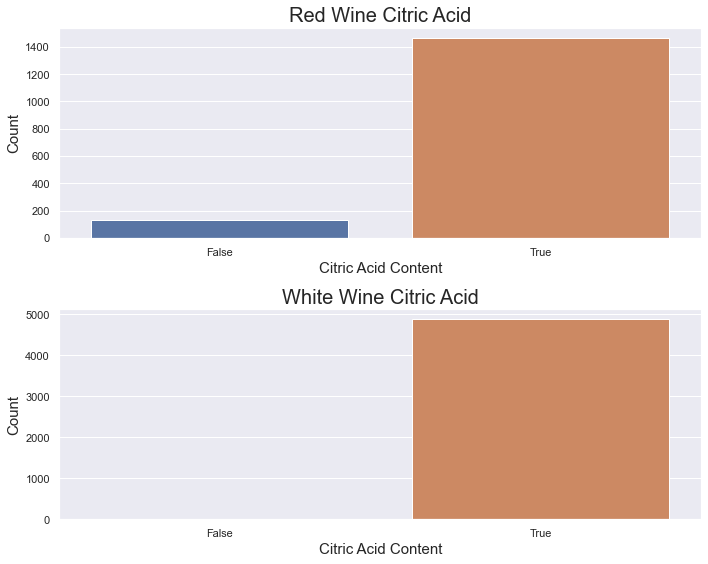

In [35]:
plt.figure(figsize=(10,8))
sns.set_theme(style='darkgrid')
plt.subplot(2,1,1)
sns.countplot(df1['citric acid'] > 0)
plt.xlabel('Citric Acid Content').set_size(15)
plt.ylabel('Count').set_size(15)
plt.title("Red Wine Citric Acid").set_size(20)
plt.tight_layout()


plt.subplot(2,1,2)
sns.countplot(df2['citric acid'] > 0)
plt.xlabel('Citric Acid Content').set_size(15)
plt.ylabel('Count').set_size(15)
plt.title("White Wine Citric Acid").set_size(20)
plt.tight_layout()


plt.show()











In the European Union, use of citric acid for acidification is prohibited, but limited use of citric acid is permitted for removing excess iron and copper from the wine if potassium ferrocyanide is not available.
From the above graph, we can infer that approximately 180-200 red wines are European.

<Figure size 720x576 with 0 Axes>

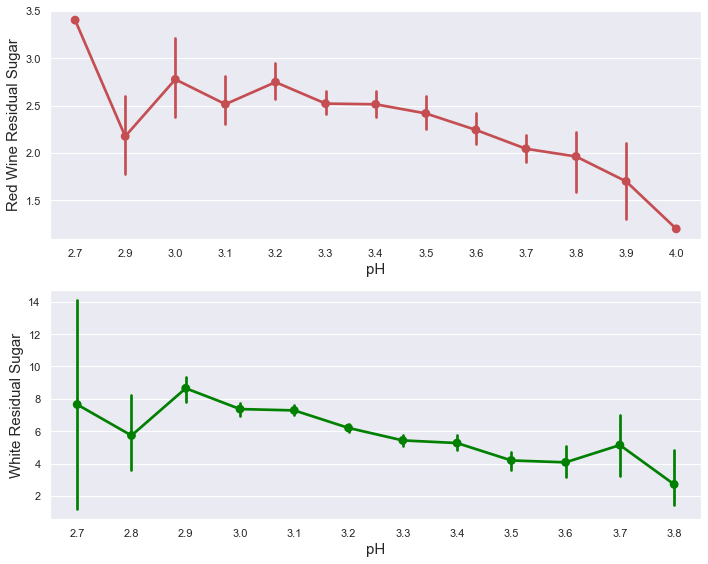

In [36]:
plt.figure(figsize=(10,8))

plt.figure(figsize=(10,8))
sns.set_theme(style='darkgrid')
plt.subplot(2,1,1)
sns.pointplot(df1['pH'].round(1),df1['residual sugar'], color='r')
plt.xlabel('pH').set_size(15)
plt.ylabel('Red Wine Residual Sugar').set_size(15)
plt.tight_layout()


plt.subplot(2,1,2)
sns.pointplot(df2['pH'].round(1),df2['residual sugar'], color='green')
plt.xlabel('pH').set_size(15)
plt.ylabel('White Residual Sugar').set_size(15)
plt.tight_layout()


plt.show()






From the graph, we can see that low levels of pH(High Acidity) have high levels of Sugar in red wines. whereas in white wines there levels of sugar is low on lower PH as well.